# Лабораторная работа 5. Линейные модели: регрессия
## Учебная задача. Прогноз популярности статьи на Хабре

In [1]:
from __future__ import division, print_function
import os
import numpy as np
import pandas as pd
import scipy
import scipy.sparse
from matplotlib import pyplot as plt
import seaborn as sns

os.makedirs("artifacts", exist_ok=True)

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction import DictVectorizer

%matplotlib inline

In [2]:
train_df = pd.read_csv('datasets/howpop/howpop_train.csv')
test_df  = pd.read_csv('datasets/howpop/howpop_test.csv')

print('/////////////////////////////////////////////')
print(train_df.head())
print('/////////////////////////////////////////////')
print(test_df.head())

/////////////////////////////////////////////
                                url        domain  post_id  \
0  https://habrahabr.ru/post/18284/  habrahabr.ru    18284   
1  https://habrahabr.ru/post/18285/  habrahabr.ru    18285   
2  https://habrahabr.ru/post/18286/  habrahabr.ru    18286   
3  https://habrahabr.ru/post/18291/  habrahabr.ru    18291   
4  https://geektimes.ru/post/18294/  geektimes.ru    18294   

             published      author     flow  polling  content_len  \
0  2008-01-01 18:19:00      @Tapac  develop    False         4305   
1  2008-01-01 18:30:00  @DezmASter   design    False         7344   
2  2008-01-01 18:34:00  @DezmASter   design    False         8431   
3  2008-01-02 01:32:00    @Taoorus   design    False         5662   
4  2008-01-02 14:34:00    @dennydo      NaN    False         3706   

                                               title  comments  favs  views  \
0     Новогодний подарок блоггерам — WordPress 2.3.2         0     0    236   
1  Сумас

In [3]:
print('/////////////////////////////////////////////')
print(train_df.head(1).T)
print('/////////////////////////////////////////////')
print(test_df.head(1).T)

/////////////////////////////////////////////
                                                               0
url                             https://habrahabr.ru/post/18284/
domain                                              habrahabr.ru
post_id                                                    18284
published                                    2008-01-01 18:19:00
author                                                    @Tapac
flow                                                     develop
polling                                                    False
content_len                                                 4305
title             Новогодний подарок блоггерам — WordPress 2.3.2
comments                                                       0
favs                                                           0
views                                                        236
votes_plus                                                   0.0
votes_minus                                 

In [4]:
print('Тестовый набор: \t', test_df.shape)
print('Обучающая выборка: \t', train_df.shape)

Тестовый набор: 	 (3990, 9)
Обучающая выборка: 	 (134137, 17)


In [5]:
print(train_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134137 entries, 0 to 134136
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   url               134137 non-null  object 
 1   domain            134137 non-null  object 
 2   post_id           134137 non-null  int64  
 3   published         134137 non-null  object 
 4   author            97657 non-null   object 
 5   flow              97048 non-null   object 
 6   polling           134137 non-null  bool   
 7   content_len       134137 non-null  int64  
 8   title             134137 non-null  object 
 9   comments          134137 non-null  int64  
 10  favs              134137 non-null  int64  
 11  views             134137 non-null  int64  
 12  votes_plus        133566 non-null  float64
 13  votes_minus       133566 non-null  float64
 14  views_lognorm     134137 non-null  float64
 15  favs_lognorm      134137 non-null  float64
 16  comments_lognorm  13

Ряд с датами столбца published
0   2008-01-01 18:19:00
1   2008-01-01 18:30:00
2   2008-01-01 18:34:00
3   2008-01-02 01:32:00
4   2008-01-02 14:34:00
Name: published, dtype: datetime64[ns]
Размер объекта Series:  (134137,)


<Axes: >

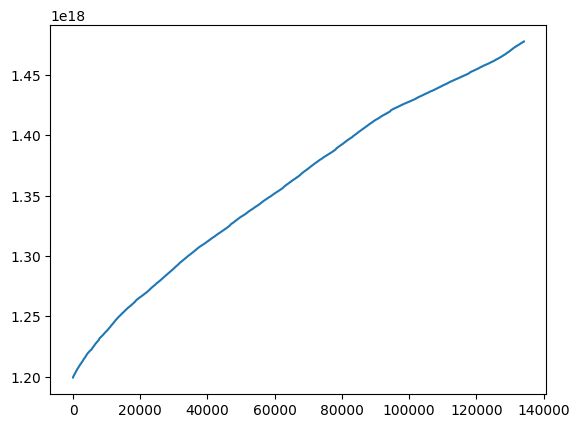

In [6]:
# копируем столбец данных published
ser_data = train_df['published'].apply(lambda ts: pd.to_datetime(ts))
print('Ряд с датами столбца published')
print(ser_data.head())
print('Размер объекта Series: ', ser_data.shape)
ser_data.apply(lambda el: el.value).plot()

In [7]:
corr = train_df.corr(numeric_only=True)
print(corr.shape)
corr

(11, 11)


,post_id,polling,content_len,comments,favs,views,votes_plus,votes_minus,views_lognorm,favs_lognorm,comments_lognorm
post_id,1.000000,0.081628,0.241384,-0.147763,0.089313,0.132385,-0.187885,-0.235594,-0.010376,-0.005845,-0.001605
polling,0.081628,1.000000,-0.003337,0.042605,0.006882,0.025660,-0.033505,0.027116,-0.003523,-0.036385,0.071417
content_len,0.241384,-0.003337,1.000000,-0.023544,0.308194,0.204101,0.068779,-0.078686,0.246063,0.356481,0.073132
comments,-0.147763,0.042605,-0.023544,1.000000,0.164166,0.290035,0.613961,0.457638,0.349568,0.278942,0.662740
favs,0.089313,0.006882,0.308194,0.164166,1.000000,0.634304,0.416241,0.062877,0.456097,0.587982,0.263239
views,0.132385,0.025660,0.204101,0.290035,0.634304,1.000000,0.396849,0.128654,0.585105,0.406782,0.326427
votes_plus,-0.187885,-0.033505,0.068779,0.613961,0.416241,0.396849,1.000000,0.464168,0.414232,0.449712,0.525081
votes_minus,-0.235594,0.027116,-0.078686,0.457638,0.062877,0.128654,0.464168,1.000000,0.146609,0.088226,0.355458
views_lognorm,-0.010376,-0.003523,0.246063,0.349568,0.456097,0.585105,0.414232,0.146609,1.000000,0.688811,0.546530
favs_lognorm,-0.005845,-0.036385,0.356481,0.278942,0.587982,0.406782,0.449712,0.088226,0.688811,1.000000,0.479476


In [8]:
corr[corr > 0.9].replace({np.nan: ''})

,post_id,polling,content_len,comments,favs,views,votes_plus,votes_minus,views_lognorm,favs_lognorm,comments_lognorm
post_id,1.0,,,,,,,,,,
polling,,1.0,,,,,,,,,
content_len,,,1.0,,,,,,,,
comments,,,,1.0,,,,,,,
favs,,,,,1.0,,,,,,
views,,,,,,1.0,,,,,
votes_plus,,,,,,,1.0,,,,
votes_minus,,,,,,,,1.0,,,
views_lognorm,,,,,,,,,1.0,,
favs_lognorm,,,,,,,,,,1.0,


published
2008     7743
2009    10783
2010    13091
2011    15063
2012    15972
2013    15537
2014    16180
2015    23452
2016    16316
Name: count, dtype: int64


Text(0.5, 1.0, 'Распределение публикаций по годам')

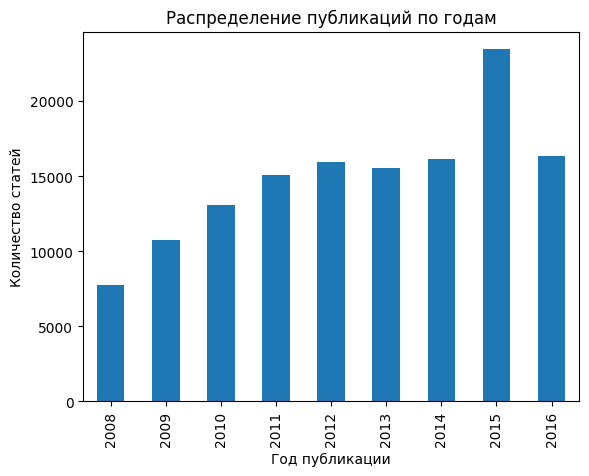

In [9]:
df = train_df.copy()
df['published'] = pd.to_datetime(df['published']).dt.year
ss = df['published'].value_counts()
print(ss.sort_index())
ss.sort_index().plot(kind='bar')
plt.xlabel('Год публикации')
plt.ylabel('Количество статей')
plt.title('Распределение публикаций по годам')

In [10]:
features = ['author', 'flow', 'domain', 'title']
train_size = int(0.7 * train_df.shape[0])
print('Размер исходного набора: ', len(train_df),
      '\nРазмер обучающей подвыборки: ', train_size)
# отделяем признаки от целевой переменной
X, y = train_df[features], train_df['favs_lognorm']
X_test = test_df[features]
X_train, X_valid = X.iloc[:train_size, :], X.iloc[train_size:, :]
y_train, y_valid = y.iloc[:train_size], y.iloc[train_size:]
print(X_train.shape, X_valid.shape, X_test.shape)

Размер исходного набора:  134137 
Размер обучающей подвыборки:  93895
(93895, 4) (40242, 4) (3990, 4)


In [11]:
vectorizer_title = TfidfVectorizer(min_df=3, max_df=0.3, ngram_range=(1, 3))

vX_train_title = vectorizer_title.fit(X_train['title'])
print('vX_train_title.vocabulary_: ', len(vX_train_title.vocabulary_))
vX_valid_title = vectorizer_title.fit(X_valid['title'])
print('vX_train_title.vocabulary_: ', len(vX_valid_title.vocabulary_))
vX_test_title = vectorizer_title.fit(X_test['title'])
print('vX_train_title.vocabulary_: ', len(vX_test_title.vocabulary_))

X_train_title = vectorizer_title.fit_transform(X_train['title'])
print('X_train_title.shape: ', X_train_title.shape)
X_valid_title = vectorizer_title.transform(X_valid['title'])
print('X_valid_title.shape: ', X_valid_title.shape)
X_test_title = vectorizer_title.transform(X_test['title'])
print('X_test_title.shape: ', X_test_title.shape)

vX_train_title.vocabulary_:  50624
vX_train_title.vocabulary_:  28528
vX_train_title.vocabulary_:  2768
X_train_title.shape:  (93895, 50624)
X_valid_title.shape:  (40242, 50624)
X_test_title.shape:  (3990, 50624)


In [12]:
dict(list(vectorizer_title.vocabulary_.items())[:10])

{'новогодний': 31497,
 'подарок': 36257,
 'блоггерам': 14241,
 'wordpress': 12172,
 'новогодний подарок': 31499,
 'сумасшедшие': 45476,
 'яйца': 50489,
 'или': 22661,
 'сервис': 42745,
 'для': 18811}

In [13]:
vectorizer_title_ch = TfidfVectorizer(analyzer='char')

vX_train_title_ch = vectorizer_title_ch.fit(X_train['title'])
print('vX_train_title_ch.vocabulary_: ', len(vX_train_title_ch.vocabulary_))
vX_valid_title_ch = vectorizer_title_ch.fit(X_valid['title'])
print('vX_valid_title_ch.vocabulary_: ', len(vX_valid_title_ch.vocabulary_))
vX_test_title_ch = vectorizer_title_ch.fit(X_test['title'])
print('vX_test_title_ch.vocabulary_: ', len(vX_test_title_ch.vocabulary_))

X_train_title_ch = vectorizer_title_ch.fit_transform(X_train['title'])
print('X_train_title_ch.shape: ', X_train_title_ch.shape)
X_valid_title_ch = vectorizer_title_ch.transform(X_valid['title'])
print('X_valid_title_ch.shape: ', X_valid_title_ch.shape)
X_test_title_ch = vectorizer_title_ch.transform(X_test['title'])
print('X_test_title_ch.shape: ', X_test_title_ch.shape)

vX_train_title_ch.vocabulary_:  218
vX_valid_title_ch.vocabulary_:  165
vX_test_title_ch.vocabulary_:  136
X_train_title_ch.shape:  (93895, 218)
X_valid_title_ch.shape:  (40242, 218)
X_test_title_ch.shape:  (3990, 218)


In [14]:
# категориальные признаки (title сюда не входит)
feats = ['author', 'flow', 'domain']

vectorizer_feats = DictVectorizer()
tmp_dict_train = X_train[feats].fillna('-').T.to_dict().values()
tmp_dict_valid = X_valid[feats].fillna('-').T.to_dict().values()
tmp_dict_test = X_test[feats].fillna('-').T.to_dict().values()

X_train_feats = vectorizer_feats.fit_transform(tmp_dict_train)
X_valid_feats = vectorizer_feats.transform(tmp_dict_valid)
X_test_feats = vectorizer_feats.transform(tmp_dict_test)
print(X_train_feats.shape)
print(X_valid_feats.shape)
print(X_test_feats.shape)

(93895, 17869)
(40242, 17869)
(3990, 17869)


In [15]:
# объединение матриц, построенных на предыдущих этапах
X_train_new = scipy.sparse.hstack([X_train_title,
                                   X_train_feats,
                                   X_train_title_ch])
X_valid_new = scipy.sparse.hstack([X_valid_title,
                                   X_valid_feats,
                                   X_valid_title_ch])
X_test_new  = scipy.sparse.hstack([X_test_title,
                                   X_test_feats,
                                   X_test_title_ch])

print(X_train_new.shape)
print(X_valid_new.shape)
print(X_test_new.shape)

(93895, 68711)
(40242, 68711)
(3990, 68711)


In [16]:
%%time
model_1 = Ridge(alpha=.1, random_state=1)
model_1.fit(X_train_new, y_train)

CPU times: total: 4.56 s
Wall time: 5.07 s


,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",1


In [17]:
train_preds1 = model_1.predict(X_train_new)
valid_preds1 = model_1.predict(X_valid_new)

print('Ошибка на трейне: ', mean_squared_error(y_train, train_preds1))
print('Ошибка на тесте: ', mean_squared_error(y_valid, valid_preds1))

Ошибка на трейне:  0.1834956756749141
Ошибка на тесте:  0.9058906901063494


In [18]:
%%time
model_2 = Ridge(alpha=1.0, random_state=1)
model_2.fit(X_train_new, y_train)

CPU times: total: 2.02 s
Wall time: 2.16 s


,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",1


In [19]:
train_preds2 = model_2.predict(X_train_new)
valid_preds2 = model_2.predict(X_valid_new)

print('Ошибка на трейне: ', mean_squared_error(y_train, train_preds2))
print('Ошибка на тесте: ', mean_squared_error(y_valid, valid_preds2))

Ошибка на трейне:  0.2862502171863612
Ошибка на тесте:  0.7012494380887055


# Индивидуальное задание. Прогноз стоимости подержанного устройства

In [20]:
import numpy as np
import pandas as pd

%matplotlib inline

from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

device = pd.read_csv('datasets/used_device/used_device_data.csv')
y = device['normalized_used_price']
print(device.shape)
print(device.isna().sum())
device.head()

(3454, 15)
device_brand               0
os                         0
screen_size                0
4g                         0
5g                         0
rear_camera_mp           179
front_camera_mp            2
internal_memory            4
ram                        4
battery                    6
weight                     7
release_year               0
days_used                  0
normalized_used_price      0
normalized_new_price       0
dtype: int64


,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
0,Honor,Android,14.50,yes,no,13.0,5.0,64.0,3.0,3020.0,146.0,2020,127,4.307572,4.715100
1,Honor,Android,17.30,yes,yes,13.0,16.0,128.0,8.0,4300.0,213.0,2020,325,5.162097,5.519018
2,Honor,Android,16.69,yes,yes,13.0,8.0,128.0,8.0,4200.0,213.0,2020,162,5.111084,5.884631
3,Honor,Android,25.50,yes,yes,13.0,8.0,64.0,6.0,7250.0,480.0,2020,345,5.135387,5.630961
4,Honor,Android,15.32,yes,no,13.0,8.0,64.0,3.0,5000.0,185.0,2020,293,4.389995,4.947837


In [21]:
# два синтезированных признака
device['camera_total'] = device['rear_camera_mp'] + device['front_camera_mp']
device['screen_area'] = device['screen_size'] ** 2

target = 'normalized_used_price'
base_num = ['screen_size', 'rear_camera_mp', 'front_camera_mp',
            'internal_memory', 'ram', 'battery', 'weight',
            'release_year', 'days_used', 'normalized_new_price']
new_num = ['camera_total', 'screen_area']
cat = ['device_brand', 'os', '4g', '5g']

train_idx, valid_idx = train_test_split(
    np.arange(len(device)), test_size=0.2, random_state=17)

def prepare(num_features):
    X = device[num_features + cat].copy()
    X_train = X.iloc[train_idx].copy()
    X_valid = X.iloc[valid_idx].copy()

    medians = X_train[num_features].median()
    X_train[num_features] = X_train[num_features].fillna(medians)
    X_valid[num_features] = X_valid[num_features].fillna(medians)

    X_train = pd.get_dummies(X_train, columns=cat, dtype=float)
    X_valid = pd.get_dummies(X_valid, columns=cat, dtype=float)
    X_valid = X_valid.reindex(columns=X_train.columns, fill_value=0.0)

    scaler = StandardScaler().fit(X_train)
    return (scaler.transform(X_train),
            scaler.transform(X_valid),
            X_train.shape[1])

def fit_and_score(num_features, alpha):
    X_train, X_valid, n_features = prepare(num_features)
    model = Ridge(alpha=alpha, random_state=1).fit(X_train, y.iloc[train_idx])
    pred = model.predict(X_valid)
    mse = mean_squared_error(y.iloc[valid_idx], pred)
    mae = mean_absolute_error(y.iloc[valid_idx], pred)
    r2 = r2_score(y.iloc[valid_idx], pred)
    return model, pred, {'MSE': mse, 'MAE': mae, 'R2': r2, 'features': n_features}

print('train:', len(train_idx), 'valid:', len(valid_idx))

train: 2763 valid: 691


In [22]:
base_model, base_pred, base_metrics = fit_and_score(base_num, alpha=1.0)
new_model, new_pred, new_metrics = fit_and_score(base_num + new_num, alpha=1.0)

comparison = pd.DataFrame([
    ['Исходные признаки', base_metrics['MSE'], base_metrics['MAE'], base_metrics['R2']],
    ['Исходные + 2 новых', new_metrics['MSE'], new_metrics['MAE'], new_metrics['R2']],
], columns=['Вариант', 'MSE', 'MAE', 'R2'])
comparison

,Вариант,MSE,MAE,R2
0,Исходные признаки,0.059463,0.185776,0.820419
1,Исходные + 2 новых,0.057246,0.181602,0.827114


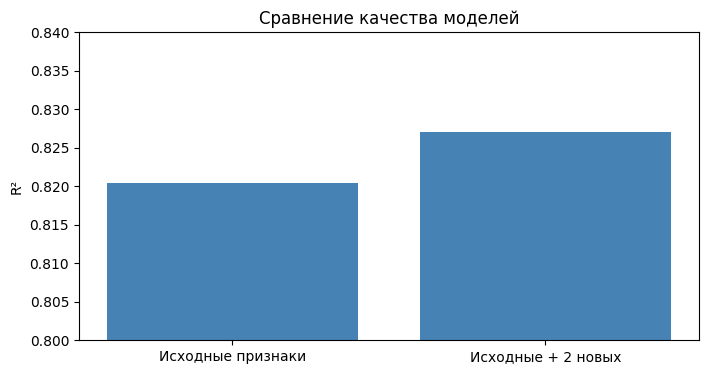

In [23]:
plt.figure(figsize=(8, 4))
plt.bar(comparison['Вариант'], comparison['R2'], color='steelblue')
plt.ylim(0.80, 0.84)
plt.ylabel('R²')
plt.title('Сравнение качества моделей')
plt.savefig('figures/fig01_regression_features.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
# подбор коэффициента регуляризации для модели с синтезированными признаками
alphas = np.logspace(-2, 3, 11)
mse_scores = []
mae_scores = []

for alpha in alphas:
    _, _, metrics = fit_and_score(base_num + new_num, alpha=alpha)
    mse_scores.append(metrics['MSE'])
    mae_scores.append(metrics['MAE'])
    print(alpha, '->', metrics['MSE'])

best_idx = int(np.argmin(mse_scores))
best_alpha = alphas[best_idx]
print('Лучшее alpha:', best_alpha)
print('Лучший MSE:', mse_scores[best_idx])

0.01 -> 0.05720947469519535
0.03162277660168379 -> 0.05721027294841401
0.1 -> 0.05721280057214385
0.31622776601683794 -> 0.05722082516382044
1.0 -> 0.057246465792591544
3.1622776601683795 -> 0.05732887136752216
10.0 -> 0.05757907983643513
31.622776601683793 -> 0.05813245839649934
100.0 -> 0.05878466339327576


316.22776601683796 -> 0.059773620889672016
1000.0 -> 0.06372377008016336
Лучшее alpha: 0.01
Лучший MSE: 0.05720947469519535


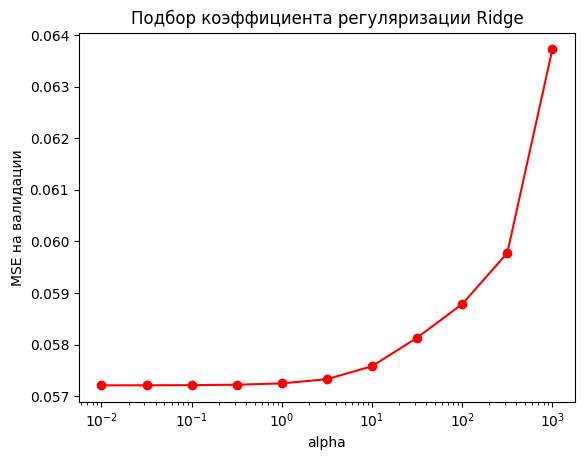

In [25]:
plt.plot(alphas, mse_scores, 'ro-')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('MSE на валидации')
plt.title('Подбор коэффициента регуляризации Ridge')
plt.savefig('figures/fig02_ridge_alpha.png', dpi=150, bbox_inches='tight')
plt.show()

Baseline MSE: 0.05946315524265873
Baseline MAE: 0.1857760312089123
Baseline R2: 0.8204194755026569
Final MSE: 0.05720947469519535
Final MAE: 0.1815056847239577
Final R2: 0.8272256588124957


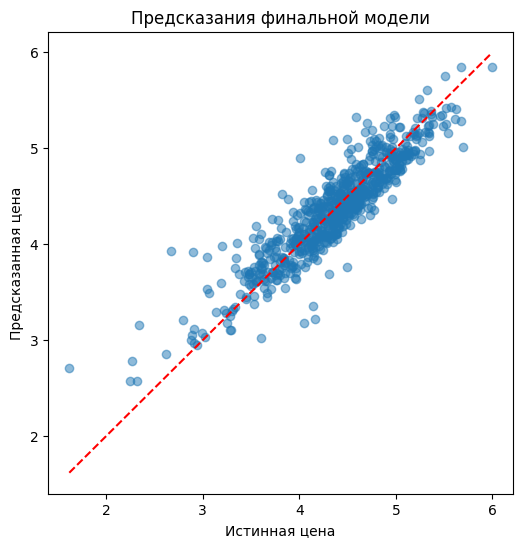

saved device_predictions.csv, device_baseline_metrics.csv, device_final_metrics.csv


In [26]:
final_model, final_pred, final_metrics = fit_and_score(
    base_num + new_num, alpha=best_alpha)

print('Baseline MSE:', base_metrics['MSE'])
print('Baseline MAE:', base_metrics['MAE'])
print('Baseline R2:', base_metrics['R2'])
print('Final MSE:', final_metrics['MSE'])
print('Final MAE:', final_metrics['MAE'])
print('Final R2:', final_metrics['R2'])

plt.figure(figsize=(6, 6))
plt.scatter(y.iloc[valid_idx], final_pred, alpha=0.5)
lims = [y.iloc[valid_idx].min(), y.iloc[valid_idx].max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Истинная цена')
plt.ylabel('Предсказанная цена')
plt.title('Предсказания финальной модели')
plt.savefig('figures/fig03_pred_vs_true.png', dpi=150, bbox_inches='tight')
plt.show()

# сохраняем baseline и финальные метрики/прогнозы
pd.DataFrame({
    'y_true': y.iloc[valid_idx].values,
    'y_pred_baseline': base_pred,
    'y_pred_final': final_pred,
}).to_csv('artifacts/device_predictions.csv', index=False)

pd.DataFrame([{
    'model': 'baseline',
    'features': ', '.join(base_num),
    'alpha': 1.0,
    **base_metrics
}]).to_csv('artifacts/device_baseline_metrics.csv', index=False)

pd.DataFrame([{
    'model': 'final',
    'features': ', '.join(base_num + new_num),
    'alpha': best_alpha,
    **final_metrics
}]).to_csv('artifacts/device_final_metrics.csv', index=False)

print('saved artifacts/device_predictions.csv, artifacts/device_baseline_metrics.csv, artifacts/device_final_metrics.csv')